# Neural Style Transfer
**Author:** [Ajim Mujawar]  
**Task 05 - Generative AI**

Apply the artistic **style** of one image (a painting) to the **content** of another image (a photo) using the neural style transfer algorithm of Gatys et al. (2015), built on a pre-trained **VGG19**.

Notebook outline: setup -> load images -> fast TF-Hub baseline -> VGG19 content/style features -> Gram matrix -> optimisation -> total variation loss -> experiments -> save results.


## 1. Setup

In [1]:
import os
import tensorflow as tf
# Load compressed models from tensorflow_hub
os.environ['TFHUB_MODEL_LOAD_FORMAT'] = 'COMPRESSED'

import IPython.display as display
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import PIL.Image
import time

mpl.rcParams['figure.figsize'] = (12, 12)
mpl.rcParams['axes.grid'] = False

os.makedirs("../outputs", exist_ok=True)
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPUs: []


In [2]:
def tensor_to_image(tensor):
    tensor = np.array(tensor) * 255
    tensor = np.clip(tensor, 0, 255).astype(np.uint8)
    if np.ndim(tensor) > 3:
        assert tensor.shape[0] == 1
        tensor = tensor[0]
    return PIL.Image.fromarray(tensor)

def load_img(path_to_img, max_dim=512):
    img = tf.io.read_file(path_to_img)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.float32)
    shape = tf.cast(tf.shape(img)[:-1], tf.float32)
    scale = max_dim / tf.reduce_max(shape)
    new_shape = tf.cast(shape * scale, tf.int32)
    img = tf.image.resize(img, new_shape)
    return img[tf.newaxis, :]

def imshow(image, title=None):
    if len(image.shape) > 3:
        image = tf.squeeze(image, axis=0)
    plt.imshow(image)
    if title:
        plt.title(title)
    plt.axis("off")

## 2. Choose the content and style images
By default we use the TensorFlow tutorial images (a Labrador photo and Kandinsky's *Composition 7*).  
**To use your own images** on Colab, run the optional upload cell below, or set `content_path` / `style_path` to your files.

In [3]:
content_path = tf.keras.utils.get_file(
    'YellowLabradorLooking_new.jpg',
    'https://storage.googleapis.com/download.tensorflow.org/example_images/YellowLabradorLooking_new.jpg')
style_path = tf.keras.utils.get_file(
    'kandinsky5.jpg',
    'https://storage.googleapis.com/download.tensorflow.org/example_images/Vassily_Kandinsky%2C_1913_-_Composition_7.jpg')

83281/83281 ━━━━━━━━━━━━━━━━━━━━ 3s 31us/step
195196/195196 ━━━━━━━━━━━━━━━━━━━━ 14s 71us/step


In [ ]:
# OPTIONAL (Colab): upload your own content and style images
# from google.colab import files
# up = files.upload()               # select two files
# content_path, style_path = list(up.keys())[:2]

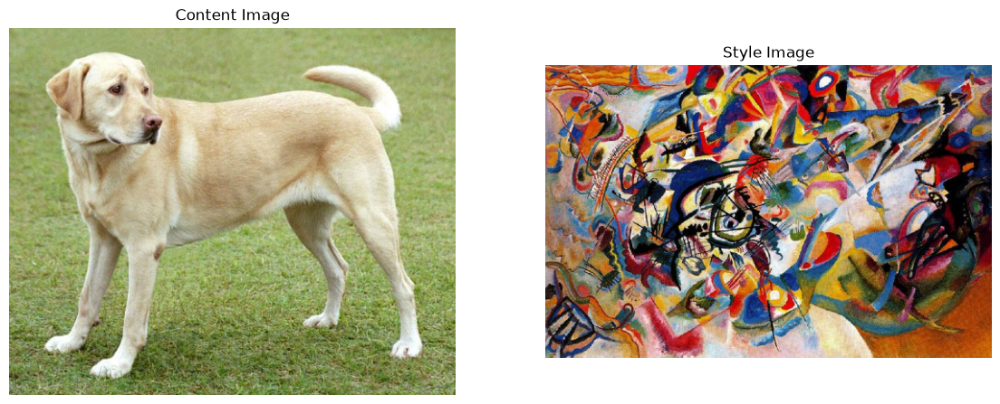

content: (1, 422, 512, 3) | style: (1, 336, 512, 3)


In [4]:
content_image = load_img(content_path)
style_image = load_img(style_path)

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1); imshow(content_image, 'Content Image')
plt.subplot(1, 2, 2); imshow(style_image, 'Style Image')
plt.show()
print("content:", content_image.shape, "| style:", style_image.shape)

In [10]:
from pathlib import Path

print("Notebook working directory:", Path.cwd())

for file in Path.cwd().rglob("*"):
    if file.is_file() and file.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
        print(file)

Notebook working directory: d:\Prodigy_Infotech_internship_task\neural-style-transfer\notebooks


In [11]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

for item in PROJECT_DIR.rglob("*"):
    if item.is_file() and item.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
        print(item)

d:\Prodigy_Infotech_internship_task\neural-style-transfer\images\my_photo.png
d:\Prodigy_Infotech_internship_task\neural-style-transfer\images\xuv_700.jpg


In [12]:
content_path = r"D:\path\to\your\actual_photo.jpg"
style_path = r"D:\Prodigy_Infotech_internship_task\neural-style-transfer\images\xuv_700.jpg"

In [15]:

from pathlib import Path

# Your local image folder
IMAGE_DIR = Path.cwd().parent / "images"

# Use your own images
content_path = str(IMAGE_DIR / "my_photo.png")
style_path = str(IMAGE_DIR / "xuv_700.jpg")

# Verify the paths
print("Content image found:", Path(content_path).exists())
print("Style image found:", Path(style_path).exists())
print("Content path:", content_path)
print("Style path:", style_path)


Content image found: True
Style image found: True
Content path: d:\Prodigy_Infotech_internship_task\neural-style-transfer\images\my_photo.png
Style path: d:\Prodigy_Infotech_internship_task\neural-style-transfer\images\xuv_700.jpg


## 3. Baseline: fast style transfer with TF-Hub
A pre-trained *arbitrary stylization* network stylises in one forward pass. We keep this result to compare against the optimisation method later.

In [6]:
%pip install tensorflow-hub

  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 1.9 MB/s eta 0:00:01
   ------------------------ --------------- 1.0/1.7 MB 2.3 MB/s eta 0:00:01
   ------------------------------------- -- 1.6/1.7 MB 2.3 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 2.1 MB/s  0:00:00
Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl (12.6 MB)

  Attempting uninstall: numpy

    Found existing installation: numpy 1.26.4

   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 6.0.1 requires huggingface-hub<2.0.0,>=1.3.0, but you have huggingface-hub 0.36.2 which is incompatible.
sentence-transformers 6.0.1 requires transformers<6.0.0,>=5.0.0, but you have transformers 4.46.3 which is incompatible.


In [16]:
%pip install --upgrade setuptools

   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---

In [19]:
%pip install "setuptools==80.9.0"

   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   -------- ------------------------------- 0.3/1.2 MB ? eta -:--:--
   ----------------- ---------------------- 0.5/1.2 MB 1.3 MB/s eta 0:00:01
   -------------------------- ------------- 0.8/1.2 MB 1.5 MB/s eta 0:00:01
   ---------------------------------- ----- 1.0/1.2 MB 1.6 MB/s eta 0:00:01
   ---------------------------------------- 1.2/1.2 MB 1.4 MB/s  0:00:01
  Attempting uninstall: setuptools
    Found existing installation: setuptools 84.2.1
    Uninstalling setuptools-84.2.1:
      Successfully uninstalled setuptools-84.2.1
Note: you may need to restart the kernel to use updated packages.


In [20]:
import tensorflow as tf
import tensorflow_hub as hub

print("TensorFlow:", tf.__version__)
print("TensorFlow Hub:", hub.__version__)

c:\Users\ADMIN\anaconda3\envs\data_science\Lib\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version



TensorFlow: 2.21.0
TensorFlow Hub: 0.16.1


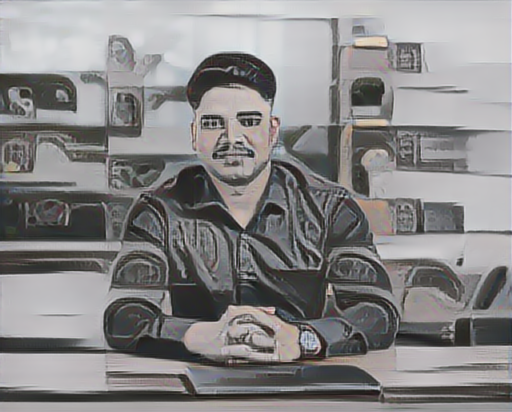

In [21]:
hub_model = hub.load(
    "https://tfhub.dev/google/magenta/arbitrary-image-stylization-v1-256/2"
)

hub_stylized = hub_model(
    tf.constant(content_image),
    tf.constant(style_image)
)[0]

tensor_to_image(hub_stylized)

## 4. Content and style representations with VGG19
We use intermediate layers of VGG19 (pre-trained on ImageNet):
- **Content:** `block5_conv2` (high-level features)
- **Style:** the first conv layer of every block, `block1_conv1` ... `block5_conv1` (textures from fine to coarse)

First, test that VGG19 sees the image correctly:

In [23]:

import tensorflow as tf

x = tf.image.resize(content_image, (224, 224))
x = tf.keras.applications.mobilenet_v2.preprocess_input(x * 255.0)

if "mobile_model" not in globals():
    mobile_model = tf.keras.applications.MobileNetV2(
        weights="imagenet",
        include_top=True
    )

probs = mobile_model(tf.cast(x, tf.float32), training=False)

top5 = tf.keras.applications.mobilenet_v2.decode_predictions(
    probs.numpy(), top=5
)[0]

[(name, round(float(p), 3)) for (_, name, p) in top5]


14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 2s 46us/step 


[('notebook', 0.519),
 ('laptop', 0.133),
 ('mouse', 0.016),
 ('hand-held_computer', 0.013),
 ('park_bench', 0.011)]

In [24]:
vgg = tf.keras.applications.VGG19(include_top=False, weights='imagenet')
print([layer.name for layer in vgg.layers])

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 22s 0us/step
['input_layer_2', 'block1_conv1', 'block1_conv2', 'block1_pool', 'block2_conv1', 'block2_conv2', 'block2_pool', 'block3_conv1', 'block3_conv2', 'block3_conv3', 'block3_conv4', 'block3_pool', 'block4_conv1', 'block4_conv2', 'block4_conv3', 'block4_conv4', 'block4_pool', 'block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_conv4', 'block5_pool']


In [25]:
content_layers = ['block5_conv2']
style_layers = ['block1_conv1', 'block2_conv1', 'block3_conv1', 'block4_conv1', 'block5_conv1']
num_content_layers = len(content_layers)
num_style_layers = len(style_layers)

In [26]:
def vgg_layers(layer_names):
    """VGG19 that returns the intermediate outputs listed in layer_names."""
    vgg = tf.keras.applications.VGG19(include_top=False, weights='imagenet')
    vgg.trainable = False
    outputs = [vgg.get_layer(name).output for name in layer_names]
    return tf.keras.Model([vgg.input], outputs)

style_extractor = vgg_layers(style_layers)
style_outputs = style_extractor(style_image * 255)

for name, output in zip(style_layers, style_outputs):
    print(f"{name:14s} shape={output.numpy().shape}  min={output.numpy().min():.1f}  "
          f"max={output.numpy().max():.1f}  mean={output.numpy().mean():.2f}")

block1_conv1   shape=(1, 303, 512, 64)  min=0.0  max=831.7  mean=24.09
block2_conv1   shape=(1, 151, 256, 128)  min=0.0  max=4396.2  mean=151.20
block3_conv1   shape=(1, 75, 128, 256)  min=0.0  max=8780.7  mean=148.25
block4_conv1   shape=(1, 37, 64, 512)  min=0.0  max=12375.7  mean=566.20
block5_conv1   shape=(1, 18, 32, 512)  min=0.0  max=3229.9  mean=49.33


## 5. Style = Gram matrix
The Gram matrix holds the correlations between feature channels averaged over all positions:

$$G^l_{cd} = \frac{\sum_{ij} F^l_{ijc}(x)F^l_{ijd}(x)}{IJ}$$

It removes spatial layout and keeps texture statistics.

In [27]:
def gram_matrix(input_tensor):
    result = tf.linalg.einsum('bijc,bijd->bcd', input_tensor, input_tensor)
    input_shape = tf.shape(input_tensor)
    num_locations = tf.cast(input_shape[1] * input_shape[2], tf.float32)
    return result / num_locations

In [28]:
class StyleContentModel(tf.keras.models.Model):
    def __init__(self, style_layers, content_layers):
        super().__init__()
        self.vgg = vgg_layers(style_layers + content_layers)
        self.style_layers = style_layers
        self.content_layers = content_layers
        self.num_style_layers = len(style_layers)
        self.vgg.trainable = False

    def call(self, inputs):
        "Expects float input in [0,1]"
        inputs = inputs * 255.0
        preprocessed_input = tf.keras.applications.vgg19.preprocess_input(inputs)
        outputs = self.vgg(preprocessed_input)
        style_outputs = outputs[:self.num_style_layers]
        content_outputs = outputs[self.num_style_layers:]
        style_outputs = [gram_matrix(s) for s in style_outputs]
        content_dict = dict(zip(self.content_layers, content_outputs))
        style_dict = dict(zip(self.style_layers, style_outputs))
        return {'content': content_dict, 'style': style_dict}

extractor = StyleContentModel(style_layers, content_layers)
results = extractor(tf.constant(content_image))
for name, output in sorted(results['style'].items()):
    print("style  ", name, output.numpy().shape)
for name, output in sorted(results['content'].items()):
    print("content", name, output.numpy().shape)

style   block1_conv1 (1, 64, 64)
style   block2_conv1 (1, 128, 128)
style   block3_conv1 (1, 256, 256)
style   block4_conv1 (1, 512, 512)
style   block5_conv1 (1, 512, 512)
content block5_conv2 (1, 25, 32, 512)


## 6. Gradient descent on the image
Targets: Gram matrices of the style image and feature maps of the content image. The output image is a `tf.Variable` initialised from the content image; we minimise

`loss = style_weight * L_style + content_weight * L_content + tv_weight * L_tv`

In [29]:
style_targets = extractor(style_image)['style']
content_targets = extractor(content_image)['content']

def clip_0_1(image):
    return tf.clip_by_value(image, clip_value_min=0.0, clip_value_max=1.0)

def run_style_transfer(steps=1000, style_weight=1e-2, content_weight=1e4, tv_weight=30,
                       learning_rate=0.02, log_every=100, show=True):
    """Optimise a copy of content_image; returns (image, history)."""
    image = tf.Variable(content_image)
    opt = tf.keras.optimizers.Adam(learning_rate=learning_rate, beta_1=0.99, epsilon=1e-1)

    @tf.function()
    def train_step(image):
        with tf.GradientTape() as tape:
            outputs = extractor(image)
            style_loss = tf.add_n([tf.reduce_mean((outputs['style'][n] - style_targets[n]) ** 2)
                                   for n in outputs['style']]) * (style_weight / num_style_layers)
            content_loss = tf.add_n([tf.reduce_mean((outputs['content'][n] - content_targets[n]) ** 2)
                                     for n in outputs['content']]) * (content_weight / num_content_layers)
            tv_loss = tv_weight * tf.reduce_sum(tf.image.total_variation(image))
            loss = style_loss + content_loss + tv_loss
        grad = tape.gradient(loss, image)
        opt.apply_gradients([(grad, image)])
        image.assign(clip_0_1(image))
        return style_loss, content_loss, tv_loss

    history = {'style': [], 'content': [], 'tv': []}
    start = time.time()
    for step in range(1, steps + 1):
        s, c, t = train_step(image)
        if step % log_every == 0:
            history['style'].append(float(s)); history['content'].append(float(c)); history['tv'].append(float(t))
            if show:
                display.clear_output(wait=True)
                display.display(tensor_to_image(image))
                print(f"step {step}/{steps}  style={float(s):.2f}  content={float(c):.2f}  tv={float(t):.2f}")
    print(f"Total time: {time.time() - start:.1f}s")
    return image.read_value(), history

### 6a. Without total variation loss
First run with `tv_weight=0` to see the high-frequency noise this basic version produces.

Total time: 630.4s


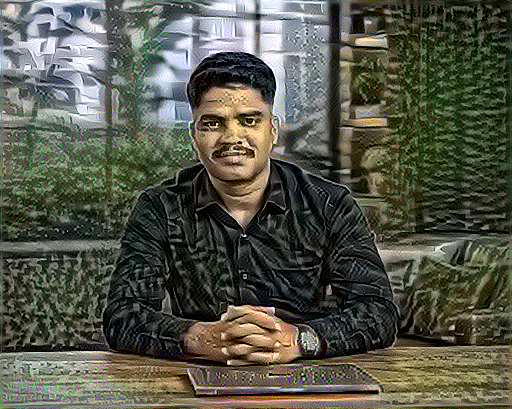

In [31]:
no_tv_image, _ = run_style_transfer(
    steps=50,
    tv_weight=0,
    show=False
)

tensor_to_image(no_tv_image)

## 7. Total variation loss
High-frequency artifacts appear as large differences between neighbouring pixels. The **total variation** loss penalises these. Visualising pixel differences (a simple edge detector):

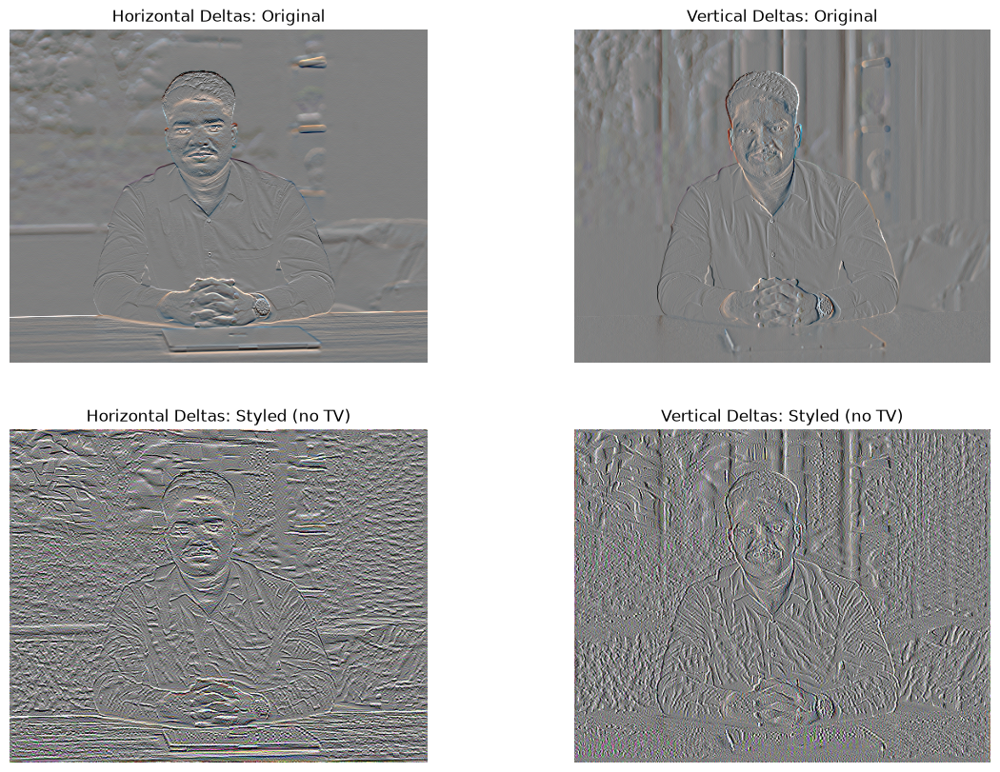

TV (original)      : [17166.754]
TV (styled, no TV) : [102454.11]


In [32]:
def high_pass_x_y(image):
    x_var = image[:, :, 1:, :] - image[:, :, :-1, :]
    y_var = image[:, 1:, :, :] - image[:, :-1, :, :]
    return x_var, y_var

plt.figure(figsize=(14, 10))
for row, (img, label) in enumerate([(content_image, "Original"), (no_tv_image, "Styled (no TV)")]):
    xd, yd = high_pass_x_y(img)
    plt.subplot(2, 2, 2 * row + 1); imshow(clip_0_1(2 * yd + 0.5), f"Horizontal Deltas: {label}")
    plt.subplot(2, 2, 2 * row + 2); imshow(clip_0_1(2 * xd + 0.5), f"Vertical Deltas: {label}")
plt.show()
print("TV (original)      :", tf.image.total_variation(content_image).numpy())
print("TV (styled, no TV) :", tf.image.total_variation(no_tv_image).numpy())

## 8. Final run (with total variation loss, 1000 steps)

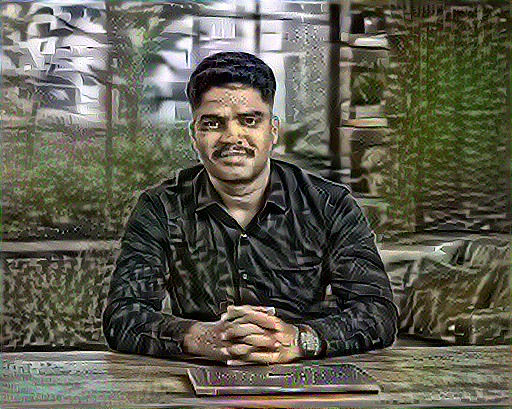

step 100/100  style=6680023.00  content=4380291.50  tv=2926399.75
Total time: 1354.3s


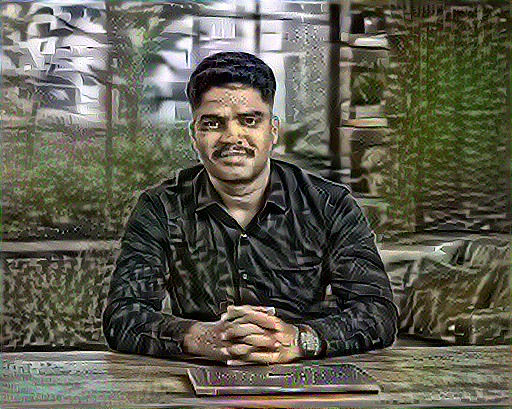

In [35]:
final_image, history = run_style_transfer(steps=100, tv_weight=30)
tensor_to_image(final_image)

History keys: dict_keys(['style', 'content', 'tv'])
style: 1 values
Sample: [6680023.0]
content: 1 values
Sample: [4380291.5]
tv: 1 values
Sample: [2926399.75]


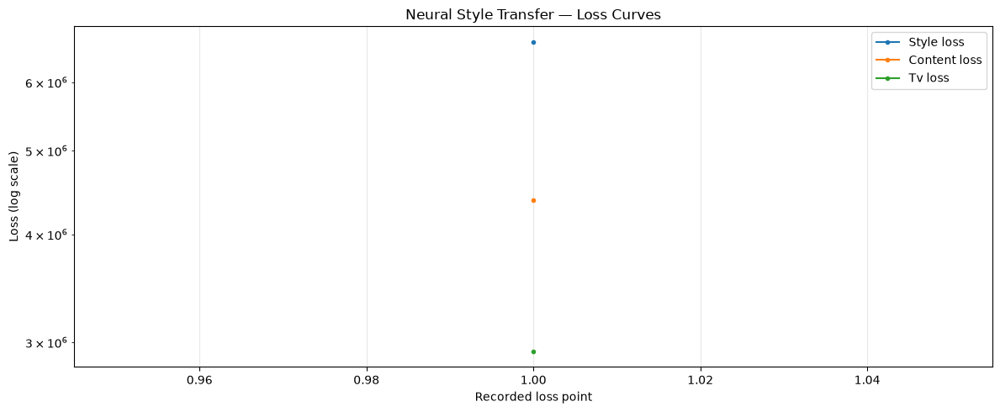

Loss curves saved to: d:\Prodigy_Infotech_internship_task\neural-style-transfer\outputs\loss_curves.png


In [37]:

from pathlib import Path
import matplotlib.pyplot as plt

# Check recorded loss values
print("History keys:", history.keys())

for key in ("style", "content", "tv"):
    values = history.get(key, [])
    print(f"{key}: {len(values)} values")
    print("Sample:", values[:5])

# Prepare output folder
OUTPUT_DIR = Path.cwd().parent / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 5))
plotted = False

for key in ("style", "content", "tv"):
    values = history.get(key, [])

    if values is None or len(values) == 0:
        print(f"Skipping '{key}': no recorded values.")
        continue

    # Convert values to ordinary Python floats
    values = [float(v) for v in values]

    # Log scale cannot display zero or negative values
    valid = [(i + 1, v) for i, v in enumerate(values)
             if v > 0 and v < float("inf")]

    if not valid:
        print(f"Skipping '{key}': no positive finite values.")
        continue

    x_values, y_values = zip(*valid)
    ax.plot(x_values, y_values, marker="o", markersize=3,
            label=f"{key.capitalize()} loss")
    plotted = True

if plotted:
    ax.set_yscale("log")
    ax.set_xlabel("Recorded loss point")
    ax.set_ylabel("Loss (log scale)")
    ax.set_title("Neural Style Transfer — Loss Curves")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()

    save_path = OUTPUT_DIR / "loss_curves.png"
    fig.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()
    print("Loss curves saved to:", save_path)
else:
    plt.close(fig)
    print("No valid loss values to plot. Check the history output above.")


## 9. Result: content + style = stylised image

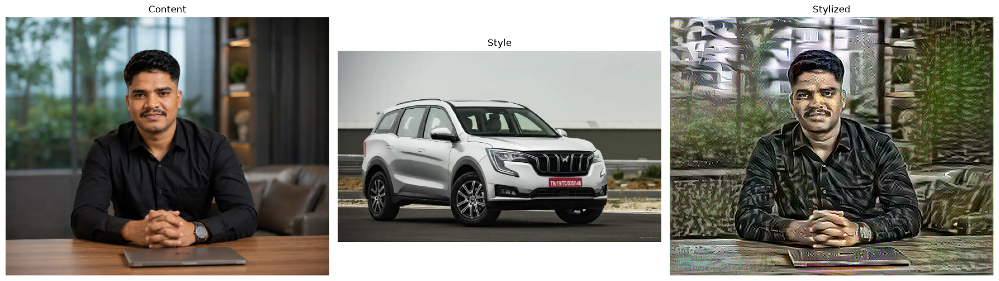

In [38]:
plt.figure(figsize=(18, 6))
for i, (img, title) in enumerate([(content_image, 'Content'), (style_image, 'Style'), (final_image, 'Stylized')]):
    plt.subplot(1, 3, i + 1); imshow(img, title)
plt.tight_layout(); plt.savefig('../outputs/comparison.png', dpi=120); plt.show()

tensor_to_image(final_image).save('../outputs/stylized-image.png')

## 10. Experiments
### 10a. Effect of the style weight
Content weight is fixed at 1e4; only the style/content ratio changes (500 steps each, for speed).

Running style_weight=0.001, steps=50...
Total time: 663.0s
Running style_weight=0.01, steps=50...
Total time: 658.3s
Running style_weight=0.1, steps=50...
Total time: 581.2s


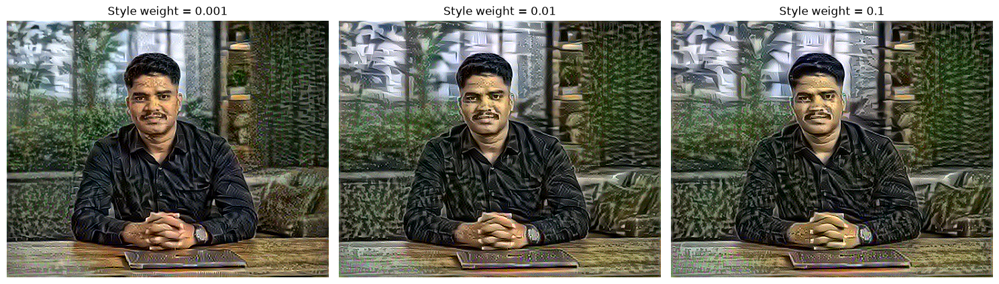

Saved to: d:\Prodigy_Infotech_internship_task\neural-style-transfer\outputs\style_weight_experiment.png


In [39]:

from pathlib import Path
import matplotlib.pyplot as plt

# Test three style weights with fewer optimization steps
weights = [1e-3, 1e-2, 1e-1]
STEPS = 50

exp_images = []

for sw in weights:
    print(f"Running style_weight={sw}, steps={STEPS}...")

    img, _ = run_style_transfer(
        steps=STEPS,
        style_weight=sw,
        show=False
    )

    exp_images.append(img)

# Create output folder
OUTPUT_DIR = Path.cwd().parent / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Compare the results
plt.figure(figsize=(15, 5))

for i, (img, sw) in enumerate(zip(exp_images, weights)):
    plt.subplot(1, 3, i + 1)
    imshow(img, f"Style weight = {sw:g}")

plt.tight_layout()

save_path = OUTPUT_DIR / "style_weight_experiment.png"
plt.savefig(save_path, dpi=100, bbox_inches="tight")
plt.show()

print("Saved to:", save_path)


### 10b. Optimisation vs. fast TF-Hub model

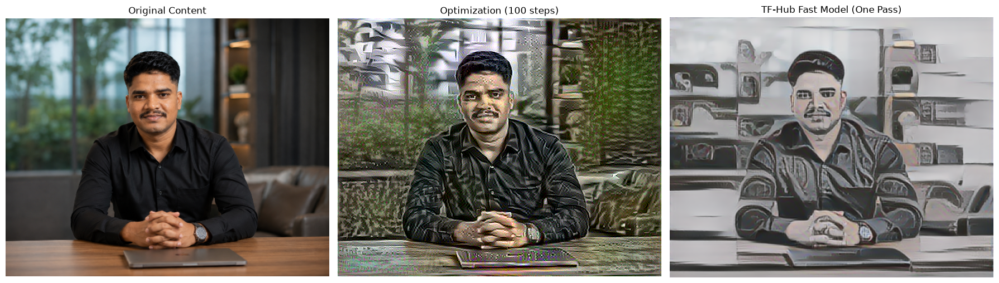

Comparison saved to: d:\Prodigy_Infotech_internship_task\neural-style-transfer\outputs\optimisation_vs_hub.png


In [40]:

# Create output folder
OUTPUT_DIR = Path.cwd().parent / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
imshow(content_image, "Original Content")

plt.subplot(1, 3, 2)
imshow(final_image, "Optimization (100 steps)")

plt.subplot(1, 3, 3)
imshow(hub_stylized, "TF-Hub Fast Model (One Pass)")

plt.tight_layout()

save_path = OUTPUT_DIR / "optimisation_vs_hub.png"
plt.savefig(save_path, dpi=120, bbox_inches="tight")
plt.show()

print("Comparison saved to:", save_path)


## 11. Conclusion
- Neural style transfer **optimises the pixels** of an image so that its VGG19 **content features** match the photo and its **Gram-matrix style statistics** match the painting.
- Deep layers describe content; Gram matrices over several layers describe style (textures, colours, strokes).
- The **style/content weight ratio** controls how strongly the style is applied; the **total variation loss** removes high-frequency noise.
- The optimisation method takes minutes per image but is flexible; the TF-Hub arbitrary-stylization model gives a stylised result in about a second.
- Limitations: Gram matrices ignore spatial layout; results depend on hyper-parameters and image choice.

*Replace this section with your own observations from your outputs.*

## 12. Try your own images
Change `content_path` and `style_path` in section 2 (for example a photo of yourself and Van Gogh's *Starry Night*), re-run the extractor cells and the final run. Use images you have the right to use.